# Complete Graph Chow Polynomial Recurrence

Explorations for the $K_{n+1} \to K_n$ recurrence for Chow polynomials.

**Algorithm outline:** See `ALGORITHM.md` in this folder — it defines the recurrence, notation, and implementation checklist. The notebook implements and tests according to that spec.

We reduce $K_{n+1}$ to $K_n$ by sequentially deleting the $n$ edges of a vertex star. The key object is the sequence of intermediate matroids $\{M^i\}$ that arise as edges are deleted.

In [1]:
import sys
import os
import json

# Add project root and the-machine to path
current_dir = os.path.abspath(os.getcwd())
# project_root: repo root (works whether cwd is repo root or explorations folder)
if os.path.exists(os.path.join(current_dir, "conclusion", "explorations on complete graphs")):
    project_root = current_dir
else:
    project_root = os.path.dirname(os.path.dirname(current_dir))
sys.path.insert(0, project_root)
sys.path.insert(0, os.path.join(project_root, "the-machine"))

from sage.all import *
from HM_module import *
from custom_matroid_functions import *

## Notation (from ALGORITHM.md)

- **$T_n$** = $\binom{n}{2}$ = number of edges in $K_n$
- **$M^i$** = matroid at step $i$ (indexed by edge labels $T_n+1 \leq i \leq T_{n+1}$)
- **$S_i(M^i)$** = valid flats at step $i$ (Component Isolation Rule, see below)

## Valid flats $S_i$ — Component Isolation Rule

$S_i$ is a *filtered subset* of $L(K_n)$, not a full lattice. At step $i$ (edge count):

- $k_{\text{del}} = T_{n+1} - i$ (star edges deleted so far)
- $v_{\text{target}} = n - k_{\text{del}}$ (vertex whose star we delete next; order: $n, n-1, \ldots, 1$)
- $V_{\text{active}} = \{1, 2, \ldots, v_{\text{target}}-1\}$ (vertices still with star edges)

$$F \in S_i \iff C_{v_{\text{target}}}(F) \cap V_{\text{active}} = \emptyset$$

where $C_v(F)$ is the connected component of the subgraph $F$ containing vertex $v$.

## Define M_i: matroid by edge count

**M_i** = matroid with $i$ edges (in our labelling). Examples:
- $M_1 = K_2$, $M_3 = K_3$, $M_6 = K_4$, $M_{10} = K_5$
- $M_{T_n} = K_n$ (triangular number $T_n = \binom{n}{2}$)

For the reduction $K_{n+1} \to K_n$, the intermediate matroids are $M_{T_n+1}, M_{T_n+2}, \ldots, M_{T_{n+1}}$.

## Labelled complete graph

Edges are labelled by **vertex addition**: add vertices 2, 3, ..., n. When adding vertex $j$, add edges $(1,j), (2,j), \ldots, (j-1,j)$ in that order:
- $(1,2) \to 1$; $(1,3) \to 2$, $(2,3) \to 3$; $(1,4) \to 4$, $(2,4) \to 5$, $(3,4) \to 6$; $(1,5) \to 7$, ...
- Star edges (incident to vertex $n+1$ in $K_{n+1}$) have the **highest labels**.
- We delete in order of **highest labels first**.

In [2]:
def T(n):
    """Triangular number: T_n = binom(n,2) = number of edges in K_n."""
    return n * (n - 1) // 2


def labelled_graph(i):
    """
    Return the labelled graph for matroid M_i (matroid with i edges).
    M1 = K2, M3 = K3, M6 = K4, M10 = K5, etc.
    
    Labelling: vertex addition order. Edges (1,2)->1, (1,3)->2, (2,3)->3, ...
    Star edges (incident to vertex n+1) have highest labels.
    
    Returns: (Graph, edge_to_label dict, label_to_edge dict)
    """
    i = int(i)
    if i == 0:
        return Graph(), {}, {}
    if i < 0:
        raise ValueError(f"i must be >= 0, got i={i}")
    # n = base vertices: T_n <= i <= T_{n+1}  =>  n = floor((1+sqrt(1+8i))/2)
    n = int((1 + (1 + 8 * i) ** 0.5) / 2)
    T_n = T(n)
    edges = []
    edge_to_label = {}
    label_to_edge = {}
    label = 1
    # Build K_n (vertices 1..n)
    for j in range(2, n + 1):
        for k in range(1, j):
            if label > i:
                break
            edges.append((k, j, label))
            edge_to_label[(k, j)] = label
            label_to_edge[label] = (k, j)
            label += 1
    # Add star edges (1,n+1), (2,n+1), ... up to edge i
    for k in range(1, n + 1):
        if label > i:
            break
        edges.append((k, n + 1, label))
        edge_to_label[(k, n + 1)] = label
        label_to_edge[label] = (k, n + 1)
        label += 1
    G = Graph(edges)
    return G, edge_to_label, label_to_edge


def labelled_graph_for_Kn(n):
    """Wrapper: return the labelled graph for K_n = M(T_n)."""
    return labelled_graph(T(n))


def matroid_from_labelled_Kn(n):
    """Matroid M(K_n) = M(T_n). Wrapper: K_n is M with T_n edges."""
    return Matroid(labelled_graph_for_Kn(n)[0])


def star_edge_labels(n):
    """Star edges of K_{n+1} (incident to vertex n+1), in deletion order (highest first)."""
    T_n = T(n)
    T_np1 = T(n + 1)
    return list(range(T_np1, T_n, -1))  # T_np1, T_np1-1, ..., T_n+1


def star_edges_from_complete_graph(n):
    """Star edges of K_{n+1} in deletion order (highest labels first)."""
    return star_edge_labels(n)


def M_i(i):
    """Matroid M_i (matroid with i edges). M1=K2, M3=K3, M6=K4, M10=K5."""
    return Matroid(labelled_graph(i)[0])

In [3]:
matroid_from_labelled_Kn(5).groundset()

frozenset({1, 2, 3, 4, 5, 6, 7, 8, 9, 10})

In [4]:
# K_4 -> K_3: matroids M_6, M_7, M_8, M_9, M_10 (T_3=6 to T_4=10)
n = 3
print(f"K_{n+1} -> K_{n}: star edges = {star_edge_labels(n)}")
for i in range(T(n), T(n+1) + 1):
    Mi = M_i(i)
    print(f"  M{i}: rank {Mi.rank()}, |E|={Mi.size()}")

K_4 -> K_3: star edges = [6, 5, 4]
  M3: rank 2, |E|=3
  M4: rank 3, |E|=4
  M5: rank 3, |E|=5
  M6: rank 3, |E|=6


## Recurrence

$$H_{K_{n+1}}(y) = (1 - ny)\, H_{K_n}(y) + \sum_{i = T_n+1}^{T_{n+1}} \sum_{F \in S_i(M^i)} y \cdot H_{n-\operatorname{rk}(F)}(y) \cdot H_{M^F}(y)$$

where $S_i$ is given by the **Component Isolation Rule**:
$$F \in S_i \iff C_{v_{\text{target}}}(F) \cap V_{\text{active}} = \emptyset$$

$M^F = M|F$ is the **restriction** (not contraction): each flat $F$ is a subgraph, so $M^F$ is the matroid on that subgraph.

In [ ]:
# Map edge-label index i (T_n+1 .. T_{n+1}) to deletion-step index (0 .. n)
# M^i corresponds to: after deleting star edges with labels > i
# So M^{T_{n+1}} = K_{n+1}, M^{T_n+1} = K_n
# Deletion step k (0..n) = after deleting first k star edges
# Star edges are ordered; need to map i -> k (or vice versa)

# Work in Laurent ring: y = x^(-2). chow_polynomial returns poly in x.
P = LaurentPolynomialRing(QQ, 'x')
x = P.gen()

def H_Kn(n):
    return get_chow_polynomial(matroids.CompleteGraphic(n))


# S_i(M^i): Component Isolation Rule (NOT a full lattice of flats)
# F in S_i  <=>  C_{v_target}(F) cap V_active = empty
#   k_del = T_{n+1} - i,  v_target = n - k_del,  V_active = {1,...,v_target-1}

S_I_CACHE_PATH = os.path.join(project_root, "conclusion", "explorations on complete graphs", "s_i_cache.json")

def _load_s_i_cache():
    """Load S_i cache from JSON. Returns dict mapping i -> list of frozensets. S_i is independent of n."""
    if not os.path.exists(S_I_CACHE_PATH):
        return {}
    try:
        with open(S_I_CACHE_PATH) as f:
            raw = json.load(f)
    except (json.JSONDecodeError, ValueError):
        return {}  # empty or corrupted file
    out = {}
    for k, v in raw.items():
        if "_" in k and isinstance(v, list):
            # old format: "5_11" -> [...]
            _, i = map(int, k.split("_"))
            out[i] = [frozenset(F) for F in v]
        elif isinstance(v, dict):
            # old nested: n -> { i -> [F, ...] }
            for i_str, flats in v.items():
                out[int(i_str)] = [frozenset(F) for F in flats]
        elif isinstance(v, list):
            # current format: i -> [F, ...]
            out[int(k)] = [frozenset(F) for F in v]
    return out

def _save_s_i_cache(cache):
    """Save S_i cache to JSON. Format: i -> [F, ...], one line per i."""
    lines = []
    for i, flats in sorted(cache.items()):
        val = json.dumps([[int(e) for e in sorted(F)] for F in flats], separators=(',', ':'))
        lines.append(f'  "{i}": {val}')
    with open(S_I_CACHE_PATH, "w") as f:
        f.write('{\n' + ',\n'.join(lines) + '\n}')

def _component_contains_active(label_to_edge, F, v_target, V_active, n):
    """Union-Find: True iff C_{v_target}(F) intersects V_active."""
    if not V_active:
        return False  # no active vertices -> always pass
    parent = {v: v for v in range(1, n + 1)}
    def find(u):
        if parent[u] != u:
            parent[u] = find(parent[u])
        return parent[u]
    def union(u, v):
        pu, pv = find(u), find(v)
        if pu != pv:
            parent[pu] = pv
    for e in F:
        if e in label_to_edge:
            u, v = label_to_edge[e]
            union(u, v)
    root_target = find(v_target)
    return any(find(v) == root_target for v in V_active)

def valid_flats_S_i(n, i, M_cur=None, use_cache=True):
    """Return S_i(M^i): flats valid for the lattice sum at step i.
    Component Isolation Rule: filter L(K_n) by C_{v_target}(F) cap V_active = empty.
    S_i is independent of n; caches by i in s_i_cache.json."""
    n, i = int(n), int(i)
    if use_cache:
        cache = _load_s_i_cache()
        if i in cache:
            return cache[i]
    M_Kn = M_i(T(n))
    base_flats = list(M_Kn.lattice_of_flats())
    _, _, label_to_edge = labelled_graph_for_Kn(n)
    k_deleted = T(n + 1) - i  # stars deleted so far
    v_target = n - k_deleted  # next vertex whose star we delete (order: n, n-1, ..., 1)
    V_active = set(range(1, v_target)) if v_target > 1 else set()
    result = [F for F in base_flats if not _component_contains_active(label_to_edge, F, v_target, V_active, n)]
    if use_cache:
        cache = _load_s_i_cache()
        cache[i] = result
        _save_s_i_cache(cache)
    return result


# H_{M^F}: M^F = M|F is the restriction. Each flat F is a subgraph, so M|F is the matroid on that subgraph.
def H_M_restrict_F(M, F):
    """H_{M|F} - Chow polynomial of M restricted to F (matroid on the subgraph F). Returns poly in x."""
    return get_chow_polynomial(M.delete(M.groundset()-F))

In [6]:
def recurrence_RHS(n):
    """RHS of H_{K_{n+1}} = (1-nx)H_{K_n} + sum over S_i.
    Uses M(K_n) for restriction: M|F = M^i|F when F in L(K_n), so we restrict M not M^i."""
    M = M_i(T(n))  # M(K_n) - same restriction M|F for any F in S_i
    base_term = (1 - n * x) * H_Kn(n)
    lattice_sum = P(0)
    for i in range(T(n) + 1, T(n + 1) + 1):  # i = edge count at each step
        for F in valid_flats_S_i(n, i):
            rkF = M.rank(F)
            m = n - rkF
            if m < 0:
                continue
            if m == 0:
                H_m = P(1)
            else:
                H_m = H_Kn(m)
            term = x * H_m * H_M_restrict_F(M, F)
            lattice_sum += term
    return base_term, lattice_sum, base_term + lattice_sum

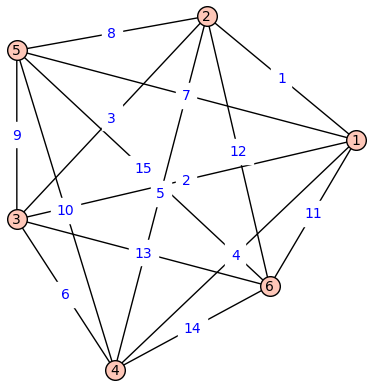

In [20]:
n = 6
labelled_graph(T(n))[0].show(edge_labels=True)

In [8]:
recurrence_RHS(n)

(1 + 181*x - 390*x^2 - 4205*x^3 - 1121*x^4 - 6*x^5,
 674*x + 9946*x^2 + 13761*x^3 + 1976*x^4 + 7*x^5,
 1 + 855*x + 9556*x^2 + 9556*x^3 + 855*x^4 + x^5)